<a href="https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/solutions/Session05_data_visualization_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۵: رسم نمودار با Matplotlib و Seaborn

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session05_data_visualization.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

کتابخانه‌ها و داده‌هایی که پاسخ‌ها به آن‌ها نیاز دارند:

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"
tips = pd.read_csv(DATA_URL + "tips.csv")
orders = pd.read_csv(DATA_URL + "orders_clean.csv", parse_dates=["order_date"])

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

توزیع `total_bill` در دادهٔ `tips` را با هیستوگرام رسم کنید. توزیع متقارن است یا چوله؟ نمودار `np.log` آن را هم رسم کنید.

</div>

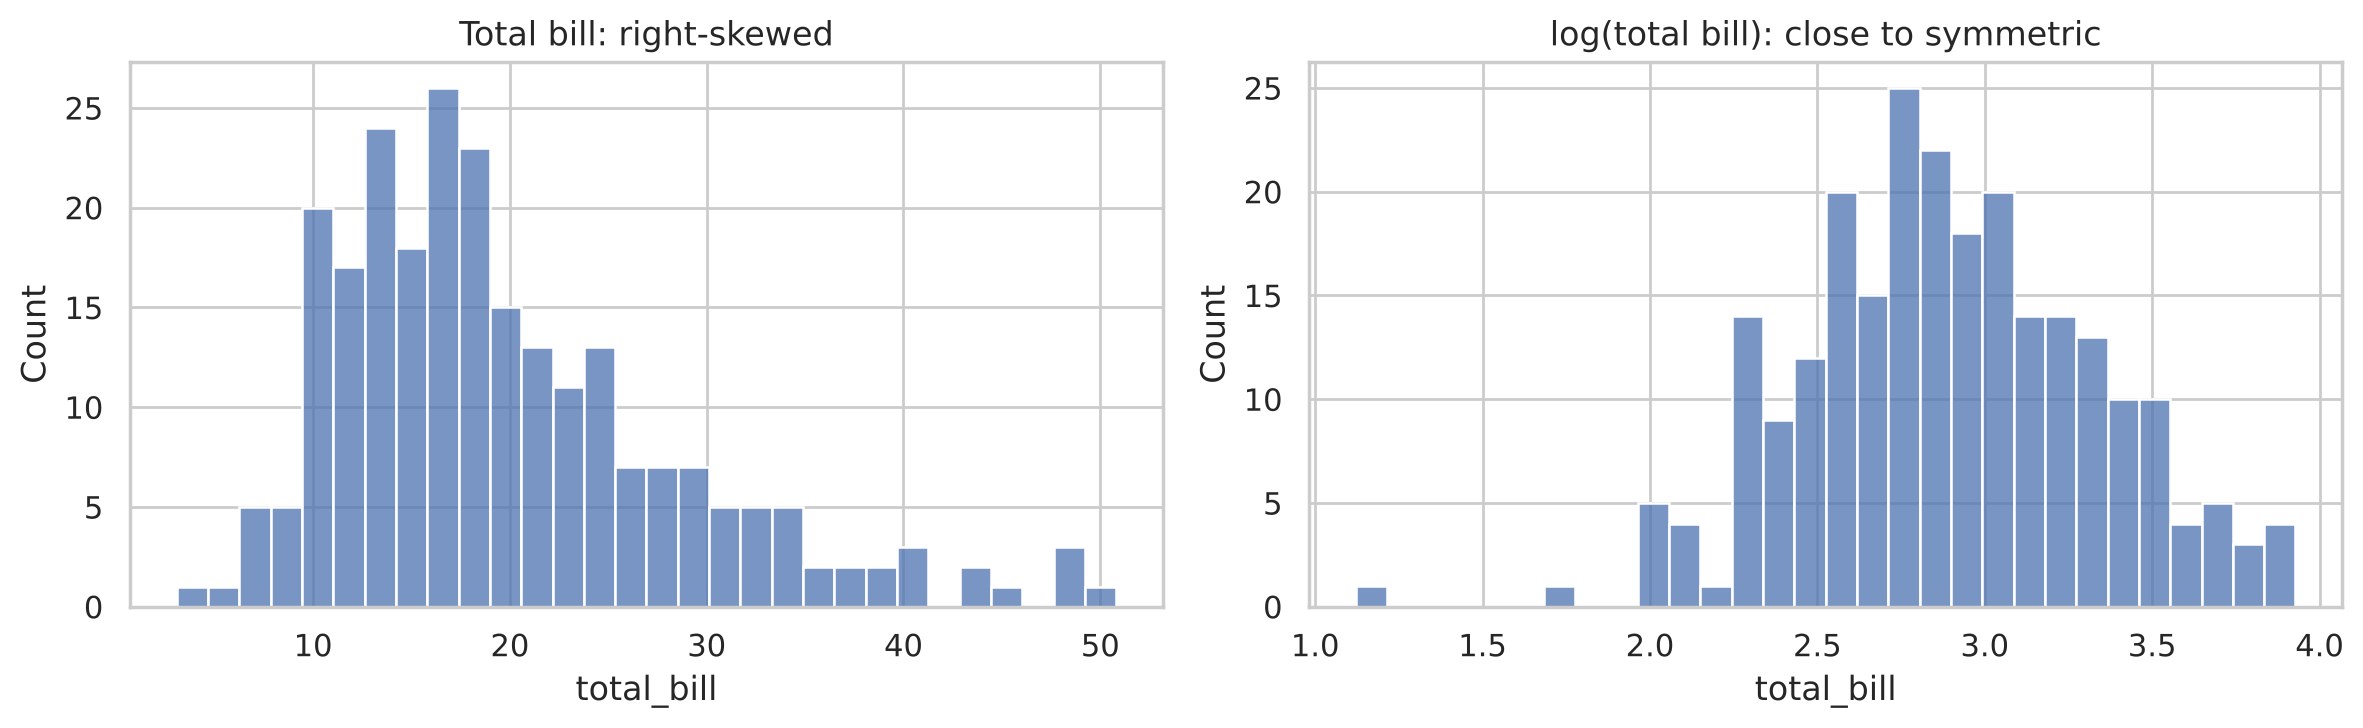

skewness: 1.13 -> -0.12


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(tips["total_bill"], bins=30, ax=axes[0])
axes[0].set_title("Total bill: right-skewed")
sns.histplot(np.log(tips["total_bill"]), bins=30, ax=axes[1])
axes[1].set_title("log(total bill): close to symmetric")
plt.tight_layout()
plt.show()
print("skewness:", tips["total_bill"].skew().round(2), "->", np.log(tips["total_bill"]).skew().round(2))

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

توزیع مبلغ صورت‌حساب **چوله به راست** است و بعد از لگاریتم تقریباً متقارن می‌شود.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

با `sns.boxplot`، مدت ارسال سفارش‌ها (`delivery_days`) را بین شهرها مقایسه کنید. شهرها را بر اساس میانه مرتب کنید.

</div>

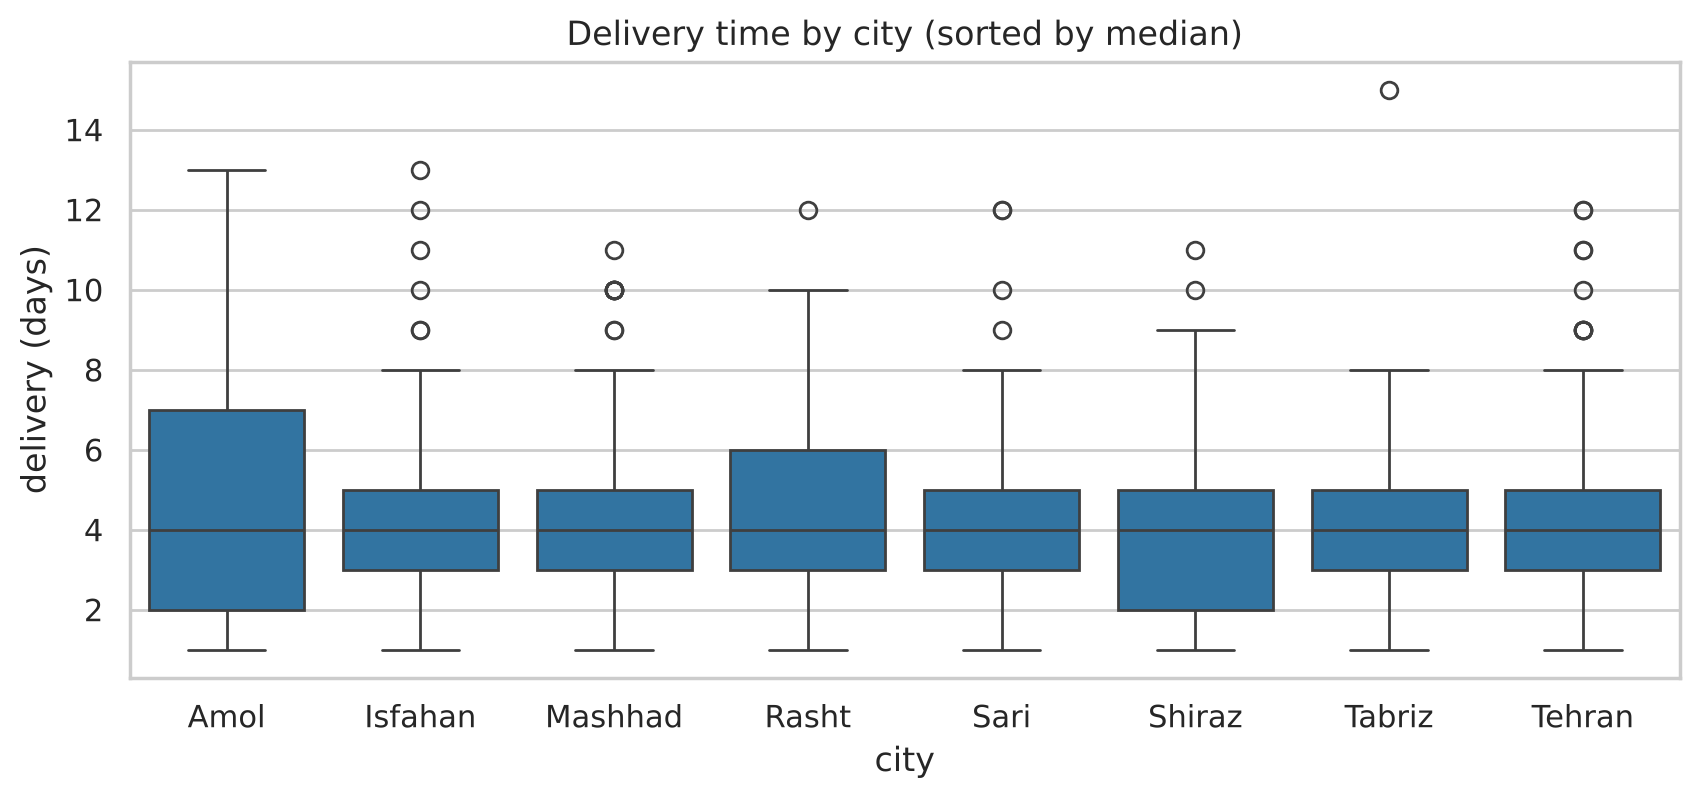

In [3]:
order = orders.groupby("city")["delivery_days"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=orders, x="city", y="delivery_days", order=order, color="tab:blue", ax=ax)
ax.set_title("Delivery time by city (sorted by median)")
ax.set_ylabel("delivery (days)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

رابطهٔ `total_bill` و `tip` را با `sns.regplot` رسم کنید. آیا رابطه برای ناهار و شام فرق دارد؟ (راهنما: `sns.lmplot` با `col="time"`)

</div>

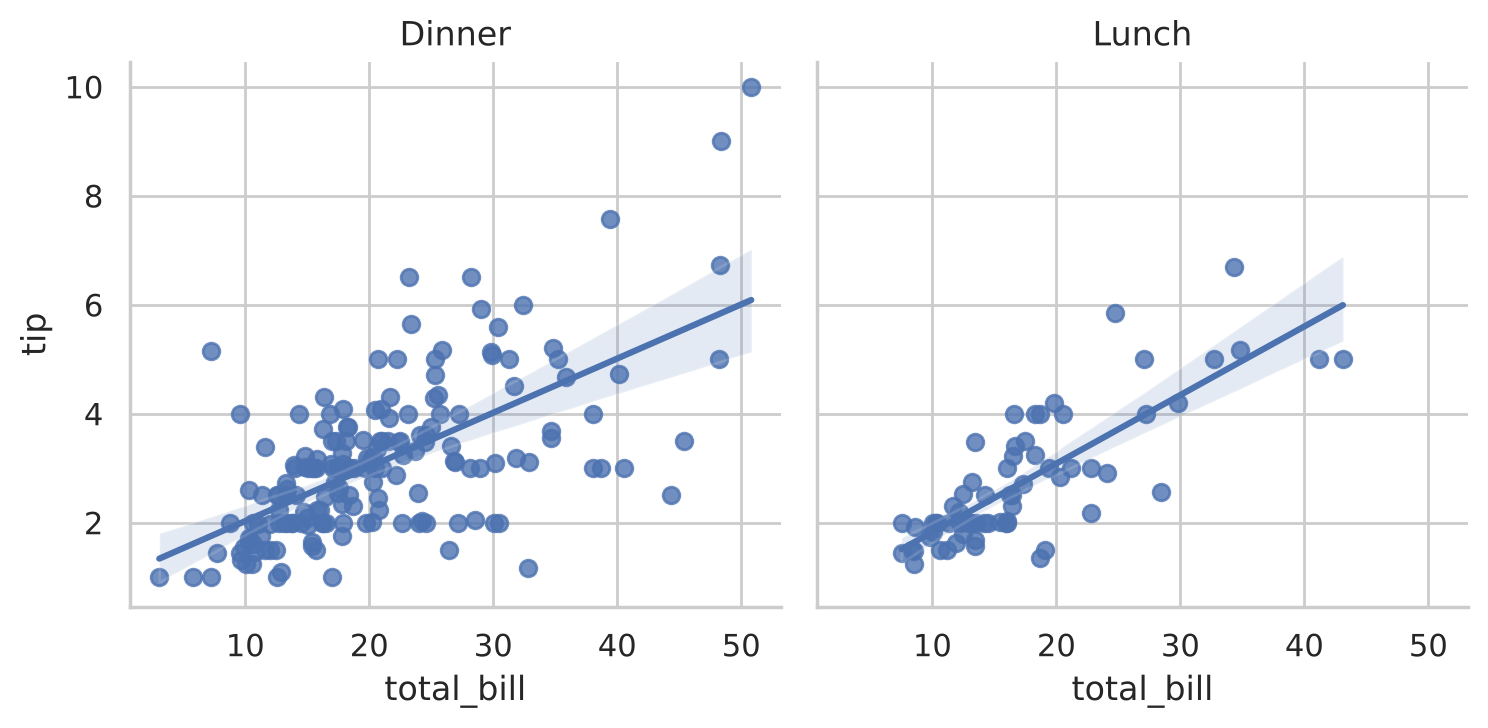

In [4]:
g = sns.lmplot(data=tips, x="total_bill", y="tip", col="time", height=3.8)
g.set_titles("{col_name}")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در هر دو وعده رابطه مثبت و تقریباً خطی است و شیب خط‌ها نزدیک به هم است؛ دادهٔ ناهار کمتر است و بازهٔ اطمینان پهن‌تری دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

نمودار میله‌ای تعداد سفارش در هر ساعت از روز را رسم کنید و عنوانی بنویسید که پیام اصلی آن را بگوید.

</div>

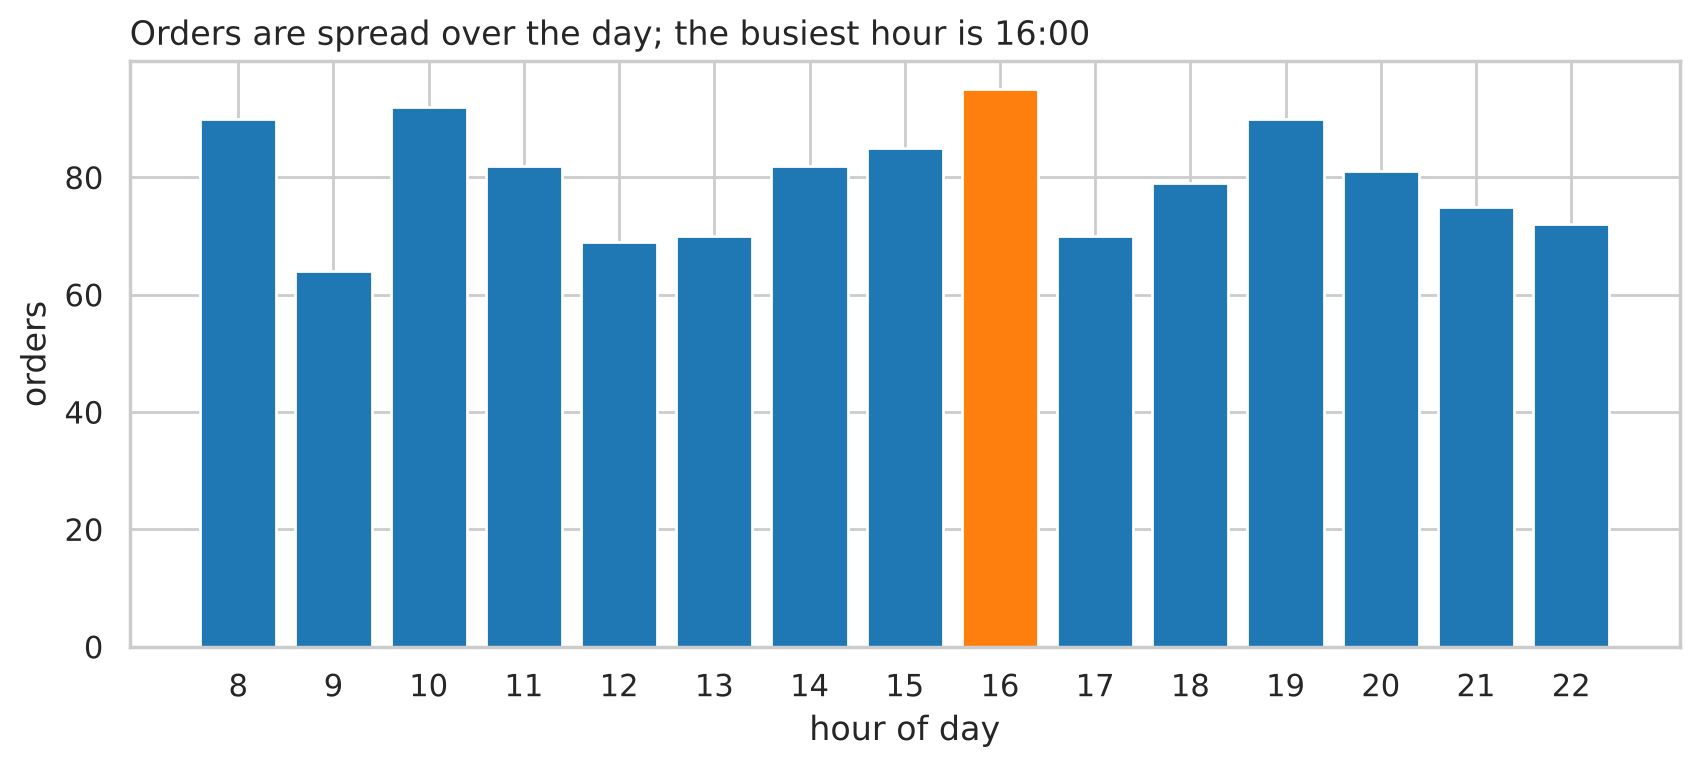

In [5]:
by_hour = orders["order_date"].dt.hour.value_counts().sort_index()
peak = by_hour.idxmax()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(by_hour.index, by_hour.values, color=["tab:orange" if h == peak else "tab:blue" for h in by_hour.index])
ax.set_xticks(by_hour.index)
ax.set_xlabel("hour of day")
ax.set_ylabel("orders")
ax.set_title(f"Orders are spread over the day; the busiest hour is {peak}:00", loc="left")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۵

یک نمودار گمراه‌کننده از دادهٔ فروشگاه بسازید و کنارش نسخهٔ صادق آن را رسم کنید. در یک جمله توضیح دهید چرا اولی گمراه‌کننده است.

</div>

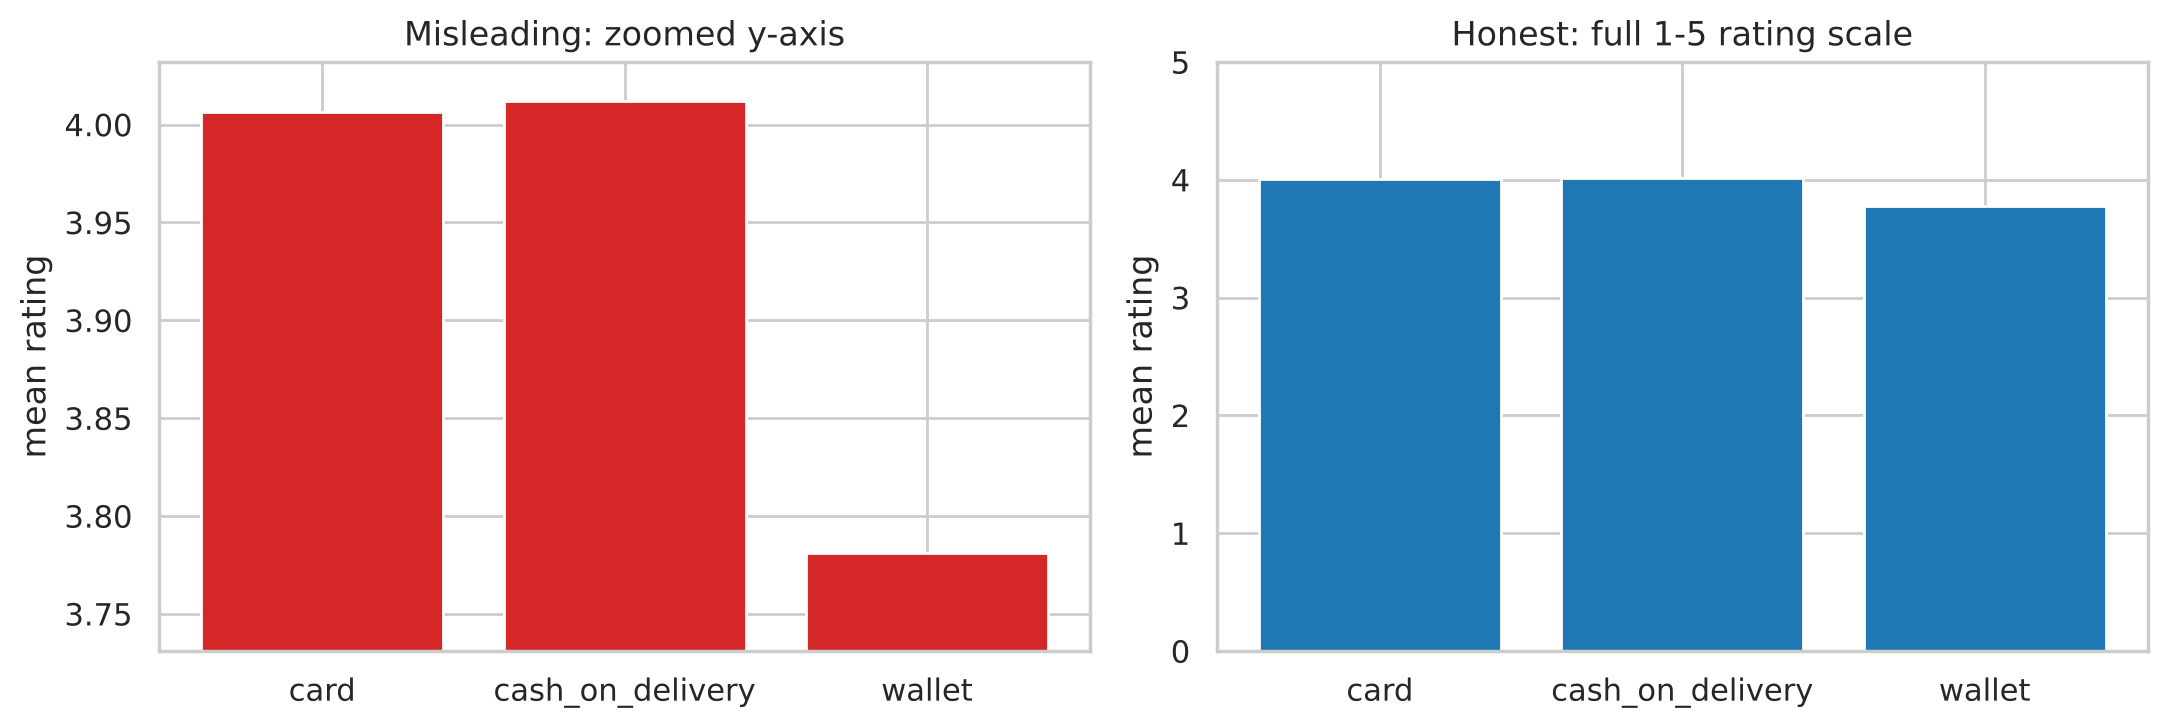

In [6]:
rating = orders.groupby("payment_method")["rating"].mean().drop("unknown")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(rating.index, rating.values, color="tab:red")
axes[0].set_ylim(rating.min() - 0.05, rating.max() + 0.02)
axes[0].set_title("Misleading: zoomed y-axis")
axes[1].bar(rating.index, rating.values, color="tab:blue")
axes[1].set_ylim(0, 5)
axes[1].set_title("Honest: full 1-5 rating scale")
for ax in axes:
    ax.set_ylabel("mean rating")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نمودار سمت چپ با بریدن محور عمودی، اختلاف چندصدمی میانگین امتیازها را بزرگ نشان می‌دهد؛ نمودار سمت راست نشان می‌دهد امتیاز سه روش پرداخت عملاً یکسان است.

</div>